# Задача 6. Компьютерное зрение: задача сегментации

* **Дедлайн**: 11.04.2025, 23:59
* **Основной полный балл**: 5
* **Максимум баллов**: 10

## Задача

Обучаем сегментацию (U-Net) на небольшом датасете селфи (2000 пар «изображение–маска»). Бенчмарк-ноутбук из задания:
https://colab.research.google.com/drive/1eUIOnLFB_9_6CJ3dVZxY9TV_gCqDAmaV

Выполнен **первый пункт** задания:

- [x] Сделать train/test split (train 1400 / val 200 / test 400), зафиксировать все сиды (random, NumPy, PyTorch,
  генераторы DataLoader'ов, разбиение) для воспроизводимости результатов;
- [x] Добавить метрику **jaccard index** (IoU);
- [x] Переобучиться на одном батче (4 картинки), проверить, что качество на нём становится почти идеальным;
- [x] Посчитать метрики (loss и jaccard) для батча и для теста;
- [x] Обучить на всём train, построить train/val кривые для **loss** и для **jaccard index**;
- [x] Подобрать оптимальное время обучения (количество шагов) для фиксированных параметров (Adam, lr = 1e-3, batch = 8);
- [x] Визуализировать top-5 самых плохих предсказаний на тесте.

Эксперименты выполнены на CPU, поэтому входное разрешение снижено с 800×600 до 168×224 (пропорции 3:4 сохранены) —
это позволяет обучить все модели за разумное время. Код при этом одинаково работает и на GPU.


## Импорты и устройство

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as tr

%matplotlib inline

In [2]:
print(f"PyTorch: {torch.__version__}")
print(f"CUDA доступна: {torch.cuda.is_available()}")

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Устройство обучения: {device}")

PyTorch: 2.14.1+cpu
CUDA доступна: False
Устройство обучения: cpu


## Константы, сиды и их фиксация

Чтобы результаты были более-менее воспроизводимы, фиксируем все сиды: Python `random`, NumPy, PyTorch (включая CUDA),
перемешивание в `DataLoader` и все перестановки при разбиении данных. Параметры обучения — как в бенчмарк-ноутбуке
из задания (Adam, lr = 1e-3).

In [3]:
SEED = 1337

import random
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

RESIZE_H, RESIZE_W = 168, 224   # разрешение, на котором обучаем (пропорции 3:4 оригинала)
SPLIT_RATIO = 0.8               # доля данных в общий пул train+val (остальное — test)
VAL_RATIO = 0.125               # доля валидации внутри пула train+val: 1600 * 0.125 = 200

OVERFIT_STEPS = 400             # число шагов при переобучении на одном батче
OVERFIT_BATCH = 4               # размер «переобучающего» батча
EPOCHS = 20                     # эпохи полного обучения
BATCH_SIZE = 8
LEARNING_RATE = 1e-3
THRESHOLD = 0.5                 # порог бинаризации вероятностей для jaccard

print(f"Разрешение: {RESIZE_H}x{RESIZE_W}, сиды зафиксированы (SEED = {SEED})")

Разрешение: 168x224, сиды зафиксированы (SEED = 1337)


## Датасет

Используется датасет из задания — сегментация человека на селфи (Selfie Segmentation, архив по ссылке из задания
скачан и распакован локально):

- 2000 пар «изображение–маска»; изображения — RGB 800×600, маски — grayscale 800×600;
- маска почти бинарная (0 — фон, 1 — человек) с мягкими краями: промежуточные значения появляются только
  на границах силуэта при сжатии изображений;
- пары однозначно сопоставляются по именам файлов.

Поиск папки с данными: пробуем несколько стандартных расположений относительно каталога блокнота.

In [4]:
NB_DIR = Path.cwd()

CANDIDATES = [
    NB_DIR.parent.parent / "data" / "selfie_dataset",   # solutions/spring -> корень репозитория
    NB_DIR.parent / "data" / "selfie_dataset",          # solutions/data/...
    NB_DIR / "dataset",
]

DATA_DIR = next((p for p in CANDIDATES if (p / "images").exists() and (p / "masks").exists()), None)
assert DATA_DIR is not None, "Папка с датасетом не найдена"
print(f"Данные: {DATA_DIR}")

images_files = sorted((DATA_DIR / "images").glob("*.jpg"))
masks_files = sorted((DATA_DIR / "masks").glob("*.png"))
print(f"Изображений: {len(images_files)}, масок: {len(masks_files)}")

Данные: /home/artemiipatov/development/my-ml/data/selfie_dataset
Изображений: 2000, масок: 2000


Посмотрим на примеры пар и на распределение доли «человека» в маске (доля пикселей со значением > 127):
это покажет, насколько разные по размеру объекты попадают в выборку.

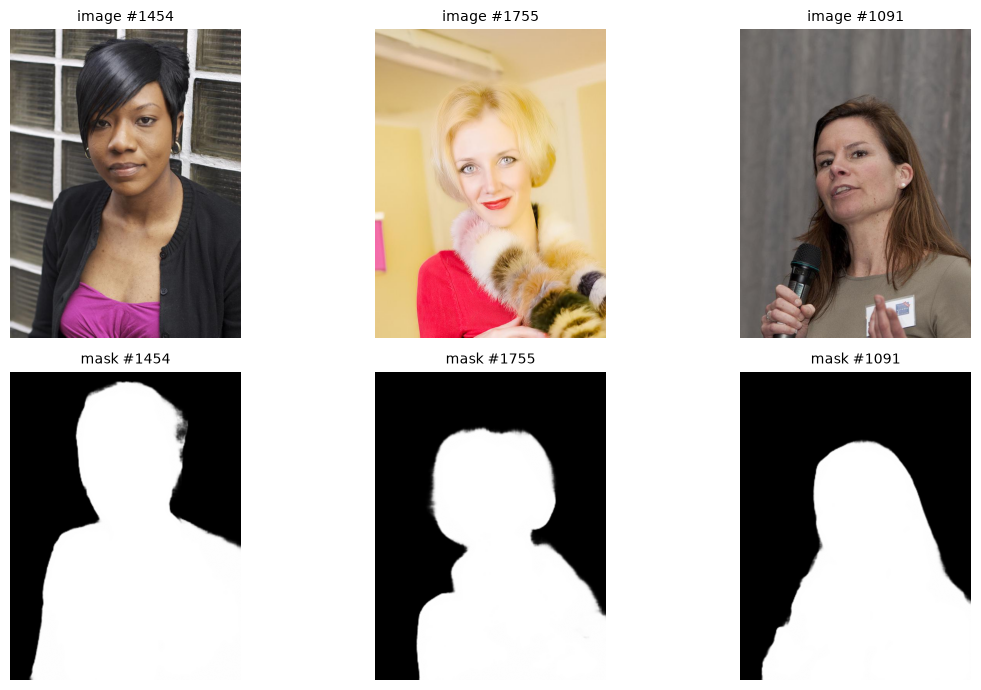

In [5]:
rng_vis = np.random.default_rng(SEED)
example_ids = rng_vis.choice(len(images_files), 3, replace=False)

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for col, i in enumerate(example_ids):
    axes[0, col].imshow(Image.open(images_files[i]))
    axes[0, col].set_title(f"image #{i}", fontsize=10)
    axes[0, col].axis("off")
    axes[1, col].imshow(Image.open(masks_files[i]), cmap="gray")
    axes[1, col].set_title(f"mask #{i}", fontsize=10)
    axes[1, col].axis("off")
plt.tight_layout()
plt.show()

Доля пикселей человека в маске: min = 0.275, mean = 0.502, max = 0.869 (4 с)


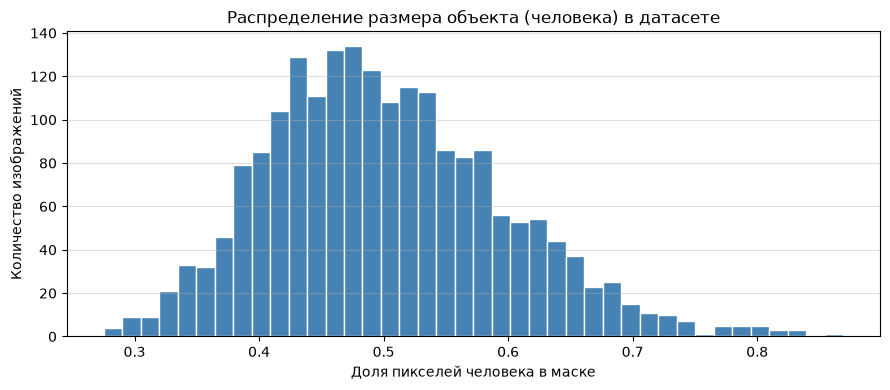

In [6]:
t0 = time.perf_counter()
person_fraction = []
for p in masks_files:
    m = np.asarray(Image.open(p).convert("L"))
    person_fraction.append((m > 127).mean())
person_fraction = np.array(person_fraction)
print(f"Доля пикселей человека в маске: min = {person_fraction.min():.3f}, "
      f"mean = {person_fraction.mean():.3f}, max = {person_fraction.max():.3f} "
      f"({time.perf_counter() - t0:.0f} с)")

plt.figure(figsize=(9, 4))
plt.hist(person_fraction, bins=40, color="steelblue", edgecolor="white")
plt.xlabel("Доля пикселей человека в маске")
plt.ylabel("Количество изображений")
plt.title("Распределение размера объекта (человека) в датасете")
plt.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

### Класс `SelfieDataset`

Класс наследуется от `Dataset` из `torch.utils.data`; при обращении по индексу открывает файлы с диска и применяет
трансформации:

- изображение: ресайз к 168×224 (билинейный) → тензор [3, 168, 224] в диапазоне [0, 1] (`ToTensor` делит на 255);
- маска: ресайз к 168×224 с интерполяцией `NEAREST` (бинарные границы не размываются) → тензор [1, 168, 224]
  в диапазоне [0, 1].

Маска подаётся в BCEWithLogitsLoss как есть (непрерывные цели), а jaccard считается после бинаризации порогом 0.5.

In [7]:
class SelfieDataset(Dataset):
    """Пары «изображение — маска» для сегментации человека на селфи."""

    def __init__(self, image_paths, mask_paths, img_size=(RESIZE_H, RESIZE_W)):
        self.image_paths = sorted(image_paths)
        self.mask_paths = sorted(mask_paths)
        assert len(self.image_paths) == len(self.mask_paths)
        self.img_transform = tr.Compose([
            tr.Resize(img_size),
            tr.ToTensor(),
        ])
        self.mask_transform = tr.Compose([
            tr.Resize(img_size, interpolation=tr.InterpolationMode.NEAREST),
            tr.ToTensor(),
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = self.img_transform(Image.open(self.image_paths[idx]).convert("RGB"))
        mask = self.mask_transform(Image.open(self.mask_paths[idx]).convert("L"))
        return image, mask

## Разбиение на train / val / test

Пары «изображение–маска» подбираются по совпадающим именам файлов (глоб отсортирован — порядок детерминирован).
Перестановки зафиксированы сидами:

1. 2000 пар → **train+val пул 80%** (1600 пар) и **test 20%** (400 пар);
2. внутри пула 1600 пар: **val 200 пар** (12.5%) и **train 1400 пар**.

Итог: train 1400 / val 200 / test 400. Валидация используется для кривых обучения и выбора числа шагов,
test — только для финальной оценки.

In [8]:
n_total = len(images_files)
perm_all = np.random.default_rng(SEED).permutation(n_total)
n_pool = int(n_total * SPLIT_RATIO)

pool_ids = perm_all[:n_pool]
test_ids = perm_all[n_pool:]

perm_pool = np.random.default_rng(SEED + 1).permutation(len(pool_ids))
n_val = int(len(pool_ids) * VAL_RATIO)

train_ids = pool_ids[perm_pool[n_val:]]
val_ids = pool_ids[perm_pool[:n_val]]

image_paths_all = [str(p) for p in images_files]
mask_paths_all = [str(p) for p in masks_files]

train_dataset = SelfieDataset([image_paths_all[i] for i in train_ids],
                              [mask_paths_all[i] for i in train_ids])
val_dataset = SelfieDataset([image_paths_all[i] for i in val_ids],
                            [mask_paths_all[i] for i in val_ids])
test_dataset = SelfieDataset([image_paths_all[i] for i in test_ids],
                             [mask_paths_all[i] for i in test_ids])

print(f"train: {len(train_dataset)} пар")
print(f"val:   {len(val_dataset)} пар")
print(f"test:  {len(test_dataset)} пар")

train: 1400 пар
val:   200 пар
test:  400 пар


## Метрика: Jaccard index

$\text{Jaccard}(A, B) = \frac{|A \cap B|}{|A \cup B|}$ — доля пересечения предсказанной и истинной масок
в их объединении, средняя по объектам. Для бинарных масок это то же самое, что IoU (Intersection over Union).
Логиты модели переводятся в бинарные предсказания через `sigmoid` и порог 0.5.

In [9]:
def jaccard_index(preds, targets, threshold=THRESHOLD):
    """Jaccard index (IoU) для батча логитов.

    signal = sigmoid(logits), сигнал бинаризуется порогом 0.5, затем для каждого объекта
    intersection / union, результат усредняется по батчу.
    """
    preds = torch.sigmoid(preds)
    preds = (preds > threshold).float()
    intersection = (preds * targets).sum(dim=(1, 2, 3))
    union = (preds + targets - preds * targets).sum(dim=(1, 2, 3))
    return (intersection / (union + 1e-8)).mean().item()

In [10]:
# проверка метрики на игрушечных примерах (логиты ±9 после sigmoid дают 0/1 далеко от порога 0.5)
def _jac_sample(pred_logit, mask_value):
    return jaccard_index(torch.tensor([[[[pred_logit]]]]), torch.tensor([[[[mask_value]]]]))

print("Jaccard совпадающих масок:", round(_jac_sample(9.0, 1.0), 4), "(ожидается 1.0)")
print("Jaccard противоположных:", round(_jac_sample(9.0, 0.0), 4), "(ожидается 0.0)")
print("Jaccard пустой и пустой (в датасете пустых масок нет):", round(_jac_sample(-9.0, 0.0), 4))
print("Jaccard половины пула объектов:", round(
    jaccard_index(torch.tensor([[[[9.0]]], [[[-9.0]]]]), torch.tensor([[[[1.0]]], [[[1.0]]]])), 4),
    "(ожидается 0.5)")

Jaccard совпадающих масок: 1.0 (ожидается 1.0)
Jaccard противоположных: 0.0 (ожидается 0.0)
Jaccard пустой и пустой (в датасете пустых масок нет): 0.0
Jaccard половины пула объектов: 0.5 (ожидается 0.5)

## Функции обучения и оценки

Функция `evaluate_loss_jaccard` считает **loss** (BCEWithLogits) и **jaccard index** на датасете в режиме инференса;
`train_model` обучает модель мини-батчным Adam, раз в эпоху валидирует на отложенной выборке, сохраняет историю
(train/val loss и jaccard по эпохам) и состояние с наилучшим val jaccard (для выбора оптимального числа шагов).

In [11]:
criterion = nn.BCEWithLogitsLoss()


def evaluate_loss_jaccard(model, dataset, device, batch_size=BATCH_SIZE):
    """Loss и средний jaccard на датасете в режиме инференса."""
    model.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    losses, jaccards = [], []
    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)
        logits = model(images)
        losses.append(criterion(logits, masks).item())
        jaccards.append(jaccard_index(logits, masks))
    return float(np.mean(losses)), float(np.mean(jaccards))

In [12]:
def train_model(model, train_dataset, val_dataset, device,
                epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LEARNING_RATE, seed=SEED, verbose=True):
    """Обучение Adam + BCEWithLogits; раз в эпоху — валидация. Возвращает (история, лучший state_dict)."""
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                              generator=torch.Generator().manual_seed(seed))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "train_jaccard": [], "val_loss": [], "val_jaccard": []}
    best_val_jaccard = -1.0
    best_state = None
    global_step = 0

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_losses, epoch_jaccards = [], []
        t0 = time.perf_counter()
        for images, masks in train_loader:
            images = images.to(device)
            masks = masks.to(device)

            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, masks)
            loss.backward()
            optimizer.step()
            global_step += 1

            epoch_losses.append(loss.item())
            epoch_jaccards.append(jaccard_index(logits.detach(), masks))

        val_loss, val_jaccard = evaluate_loss_jaccard(model, val_dataset, device, batch_size=batch_size)

        history["train_loss"].append(float(np.mean(epoch_losses)))
        history["train_jaccard"].append(float(np.mean(epoch_jaccards)))
        history["val_loss"].append(val_loss)
        history["val_jaccard"].append(val_jaccard)

        if val_jaccard > best_val_jaccard:
            best_val_jaccard = val_jaccard
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        if verbose:
            print(f"эпоха {epoch:2d} | шаг {global_step:5d}/{epochs * len(train_loader)} | "
                  f"train loss {history['train_loss'][-1]:.4f} jacc {history['train_jaccard'][-1]:.4f} | "
                  f"val loss {val_loss:.4f} jacc {val_jaccard:.4f} | {time.perf_counter() - t0:.0f} с")

    return history, best_state

## Архитектура: U-Net

Архитектура взята из бенчмарк-ноутбука из задания:

- **энкодер**: 4 уровня по 2 свёрточных блока `Conv3×3 + BatchNorm + ReLU` с `MaxPool2d(2)` между уровнями,
  затем «бутылочное горлышко» (ещё 2 блока);
- **декодер**: `ConvTranspose2d` с шагом 2 (увеличение в 2 раза) + 2 свёрточных блока, skip-соединения
  конкатенацией с согласованием пространственных размеров (дополнение нулями);
- выход: `Conv 1×1`, 1 канал — логит (BCEWithLogitsLoss).

Каналы: 3 → 16 → 32 → 64 → 128 → 256 → 128 → 64 → 32 → 16 → 1.

In [13]:
class CNNBlock(nn.Module):
    """Свёрточный блок: Conv3x3 + BatchNorm + ReLU."""

    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=0):
        super(CNNBlock, self).__init__()
        self.seq_block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.seq_block(x)


class CNNBlocks(nn.Module):
    """Несколько подряд идущих свёрточных блоков (по умолчанию 2)."""

    def __init__(self, n_conv, in_channels, out_channels, padding):
        super(CNNBlocks, self).__init__()
        self.layers = nn.ModuleList()
        for _ in range(n_conv):
            self.layers.append(CNNBlock(in_channels, out_channels, padding=padding))
            in_channels = out_channels

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x


class Encoder(nn.Module):
    """Энкодер: n_down уровней [2 свёрточных блока + MaxPool], затем бутылочное горлышко."""

    def __init__(self, in_channels, out_channels, padding, n_down=4):
        super(Encoder, self).__init__()
        self.enc_layers = nn.ModuleList()
        for _ in range(n_down):
            self.enc_layers.extend([
                CNNBlocks(n_conv=2, in_channels=in_channels, out_channels=out_channels, padding=padding),
                nn.MaxPool2d(2, 2)
            ])
            in_channels = out_channels
            out_channels *= 2

        self.enc_layers.append(CNNBlocks(n_conv=2, in_channels=in_channels, out_channels=out_channels, padding=padding))

    def forward(self, x):
        connections = []
        for layer in self.enc_layers:
            x = layer(x)
            if isinstance(layer, CNNBlocks):
                connections.append(x)
        return x, connections


class Decoder(nn.Module):
    """Декодер: n_up уровней [ConvTranspose2d x2 + 2 свёрточных блока со skip-соединением], выход Conv1x1."""

    def __init__(self, in_channels, out_channels, exit_channels, padding, n_up=4):
        super(Decoder, self).__init__()
        self.exit_channels = exit_channels
        self.layers = nn.ModuleList()

        for _ in range(n_up):
            self.layers.extend([
                nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2),
                CNNBlocks(n_conv=2, in_channels=in_channels, out_channels=out_channels, padding=padding)
            ])
            in_channels //= 2
            out_channels //= 2

        self.layers.append(nn.Conv2d(in_channels, self.exit_channels, kernel_size=1, padding=0))

    def forward(self, x, connections):
        connections.pop(-1)
        for layer in self.layers:
            if isinstance(layer, CNNBlocks):
                connections_current = connections.pop(-1)
                dim_4 = connections_current.size(3) - x.size(3)
                dim_3 = connections_current.size(2) - x.size(2)
                if dim_4 != 0 or dim_3 != 0:
                    x = nn.functional.pad(x, [0, dim_4, 0, dim_3])
                x = torch.cat([x, connections_current], dim=1)

            x = layer(x)
        return x


class UNET(nn.Module):
    """U-Net: энкодер + декодер со skip-соединениями."""

    def __init__(self, in_channels, first_out_channels, exit_channels, n_down=4, padding=1):
        super(UNET, self).__init__()
        self.encoder = Encoder(in_channels, first_out_channels, padding=padding, n_down=n_down)
        self.decoder = Decoder(first_out_channels * (2 ** n_down),
                               first_out_channels * (2 ** (n_down - 1)),
                               exit_channels, padding=padding, n_up=n_down)

    def forward(self, x):
        enc_out, connections = self.encoder(x)
        return self.decoder(enc_out, connections)

In [14]:
model_check = UNET(3, 16, 1)
n_params = sum(p.numel() for p in model_check.parameters())
print(f"Параметров модели: {n_params:,}")

x = torch.randn(2, 3, RESIZE_H, RESIZE_W)
out = model_check(x)
print(f"Вход:  {tuple(x.shape)}")
print(f"Выход: {tuple(out.shape)}")
assert out.shape[2:] == x.shape[2:], "Пространственные размеры выхода должны совпадать с входом"

Параметров модели: 1,942,577


Вход:  (2, 3, 168, 224)
Выход: (2, 1, 168, 224)


## Эксперимент 1. Переобучение на одном батче (4 картинки)

Цель — проверить, что модель способна выучить конкретные примеры «почти идеально» (проверка ёмкости модели
и корректности процедуры обучения). Берём фиксированный (сидом) батч из 4 изображений train и обучаем на нём
400 шагов Adam (lr = 1e-3). После обучения считаем метрики **для этого же батча** и **для всего теста**:
на батче качество должно быть почти идеальным, на тесте — заметно ниже (модель запомнила примеры, но не обобщила).

Индексы переобучающего батча в train: [1160 1104 1378  396]
Размер батча: (4, 3, 168, 224)


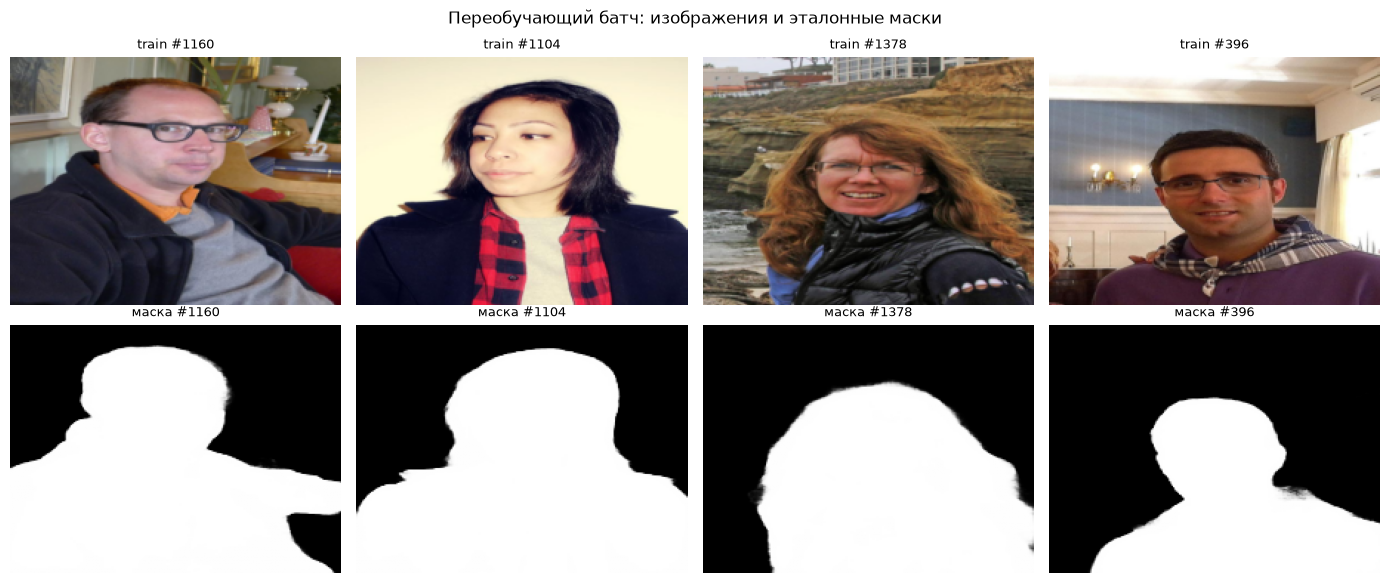

In [15]:
overfit_idx = np.random.default_rng(SEED + 2).choice(len(train_dataset), size=OVERFIT_BATCH, replace=False)
overfit_batch = [train_dataset[i] for i in overfit_idx]
images_batch = torch.stack([b[0] for b in overfit_batch]).to(device)
masks_batch = torch.stack([b[1] for b in overfit_batch]).to(device)
print("Индексы переобучающего батча в train:", overfit_idx)
print("Размер батча:", tuple(images_batch.shape))

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for k in range(OVERFIT_BATCH):
    img = images_batch[k].permute(1, 2, 0).cpu().numpy()
    mask = masks_batch[k, 0].cpu().numpy()
    axes[0, k].imshow(img)
    axes[0, k].set_title(f"train #{overfit_idx[k]}", fontsize=9)
    axes[0, k].axis("off")
    axes[1, k].imshow(mask, cmap="gray")
    axes[1, k].set_title(f"маска #{overfit_idx[k]}", fontsize=9)
    axes[1, k].axis("off")
plt.suptitle("Переобучающий батч: изображения и эталонные маски")
plt.tight_layout()
plt.show()

До обучения модель практически ничего не умеет: зафиксируем её показатели на переобучающем батче и на тесте
(«нулевая точка»). Затем обучаем 400 шагов только на этих 4 картинках, каждые 25 шагов записывая loss и jaccard
на батче.

In [16]:
model = UNET(3, 16, 1).to(device)

# «нулевая точка»: метрики ещё необученной модели на батче и на тесте
model.eval()
with torch.no_grad():
    logits_init = model(images_batch)
    init_batch_loss = criterion(logits_init, masks_batch).item()
    init_batch_jaccard = jaccard_index(logits_init, masks_batch)
init_test_loss, init_test_jaccard = evaluate_loss_jaccard(model, test_dataset, device)
print(f"До обучения: batch loss = {init_batch_loss:.4f}, batch jaccard = {init_batch_jaccard:.4f} | "
      f"test loss = {init_test_loss:.4f}, test jaccard = {init_test_jaccard:.4f}")

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

steps_log = []
t0 = time.perf_counter()
for step in range(1, OVERFIT_STEPS + 1):
    model.train()
    optimizer.zero_grad()
    logits = model(images_batch)
    loss = criterion(logits, masks_batch)
    loss.backward()
    optimizer.step()
    if step % 25 == 0:
        model.eval()
        with torch.no_grad():
            steps_log.append((step, jaccard_index(model(images_batch), masks_batch), loss.item()))
model.eval()

print(f"Переобучение завершено: {OVERFIT_STEPS} шагов за {time.perf_counter() - t0:.0f} с")
for step, jacc, l in steps_log:
    print(f"шаг {step:4d}: batch jaccard = {jacc:.4f}, batch loss = {l:.4f}")

overfit_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

До обучения: batch loss = 0.6960, batch jaccard = 0.5223 | test loss = 0.7014, test jaccard = 0.4996


Переобучение завершено: 400 шагов за 171 с
шаг   25: batch jaccard = 0.2518, batch loss = 0.2659
шаг   50: batch jaccard = 0.9690, batch loss = 0.2065
шаг   75: batch jaccard = 0.9891, batch loss = 0.1631
шаг  100: batch jaccard = 0.9899, batch loss = 0.1306
шаг  125: batch jaccard = 0.9901, batch loss = 0.1061
шаг  150: batch jaccard = 0.9899, batch loss = 0.0882
шаг  175: batch jaccard = 0.9904, batch loss = 0.0735
шаг  200: batch jaccard = 0.9904, batch loss = 0.0628
шаг  225: batch jaccard = 0.9903, batch loss = 0.0543
шаг  250: batch jaccard = 0.9906, batch loss = 0.0476
шаг  275: batch jaccard = 0.9904, batch loss = 0.0426
шаг  300: batch jaccard = 0.9906, batch loss = 0.0382
шаг  325: batch jaccard = 0.9907, batch loss = 0.0347
шаг  350: batch jaccard = 0.9907, batch loss = 0.0321
шаг  375: batch jaccard = 0.9907, batch loss = 0.0295
шаг  400: batch jaccard = 0.9906, batch loss = 0.0278


In [17]:
# метрики на переобучающем батче и на тесте
with torch.no_grad():
    final_batch_loss = criterion(model(images_batch), masks_batch).item()
    final_batch_jaccard = jaccard_index(model(images_batch), masks_batch)
final_test_loss, final_test_jaccard = evaluate_loss_jaccard(model, test_dataset, device)

overfit_summary = pd.DataFrame({
    "loss": [init_batch_loss, final_batch_loss, init_test_loss, final_test_loss],
    "jaccard": [init_batch_jaccard, final_batch_jaccard, init_test_jaccard, final_test_jaccard],
}, index=["batch, до обучения", "batch, после переобучения", "test, до обучения", "test, после переобучения"])
print(overfit_summary.round(4))

                             loss  jaccard
batch, до обучения         0.6960   0.5223
batch, после переобучения  0.0269   0.9906
test, до обучения          0.7014   0.4996
test, после переобучения   1.2438   0.5344


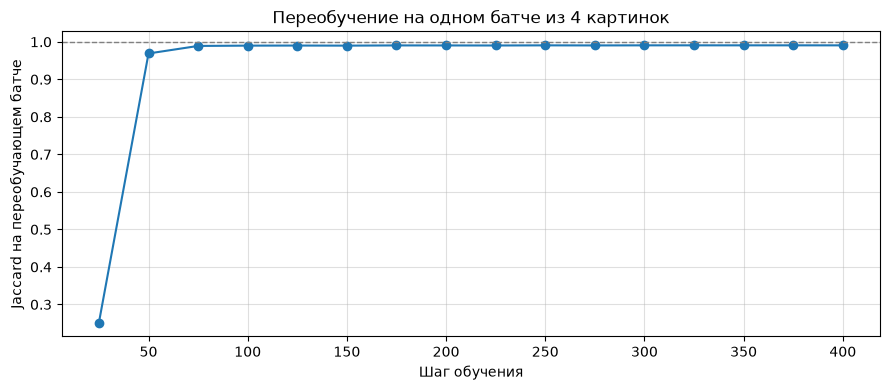

In [18]:
steps_ar = np.array(steps_log)
plt.figure(figsize=(9, 4))
plt.plot(steps_ar[:, 0], steps_ar[:, 1], marker="o", linewidth=1.5)
plt.axhline(1.0, color="gray", linestyle="--", linewidth=1)
plt.xlabel("Шаг обучения")
plt.ylabel("Jaccard на переобучающем батче")
plt.title("Переобучение на одном батче из 4 картинок")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

In [19]:
def plot_triplets(images, masks, preds, titles, figsize=(12, 5)):
    """Тройки: изображение | предсказание | истинная маска."""
    n = len(images)
    fig, axes = plt.subplots(n, 3, figsize=figsize)
    if n == 1:
        axes = axes[None, :]
    for i in range(n):
        img = images[i].permute(1, 2, 0).cpu().numpy()
        mask = masks[i, 0].cpu().numpy()
        axes[i, 0].imshow(img)
        axes[i, 0].set_title(titles[0], fontsize=10)
        axes[i, 0].axis("off")
        axes[i, 1].imshow(preds[i], cmap="gray")
        axes[i, 1].set_title(titles[1], fontsize=10)
        axes[i, 1].axis("off")
        axes[i, 2].imshow(mask, cmap="gray")
        axes[i, 2].set_title(titles[2], fontsize=10)
        axes[i, 2].axis("off")
    plt.tight_layout()
    plt.show()


def get_preds(model, images, device):
    """Бинарные предсказания модели (sigmoid + порог 0.5)."""
    model.eval()
    with torch.no_grad():
        logits = model(images.to(device))
        return (torch.sigmoid(logits).cpu().numpy() > THRESHOLD).astype(np.float32).squeeze(1)

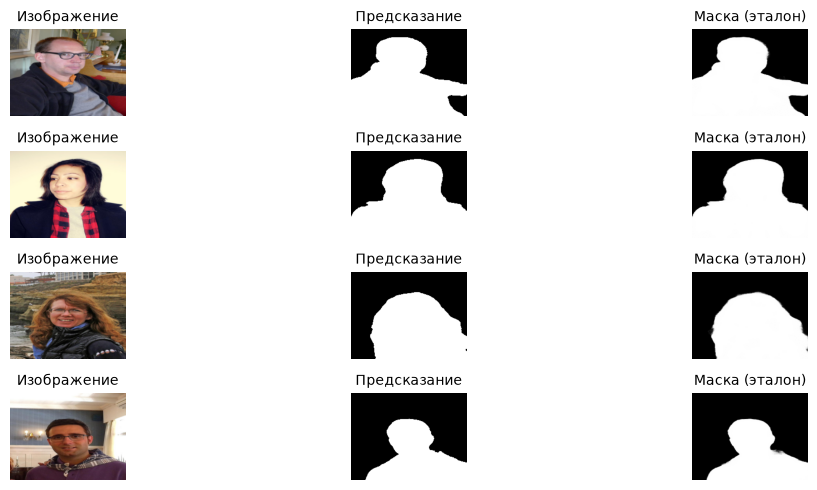

test #183: jaccard = 0.7812
test #14: jaccard = 0.9113


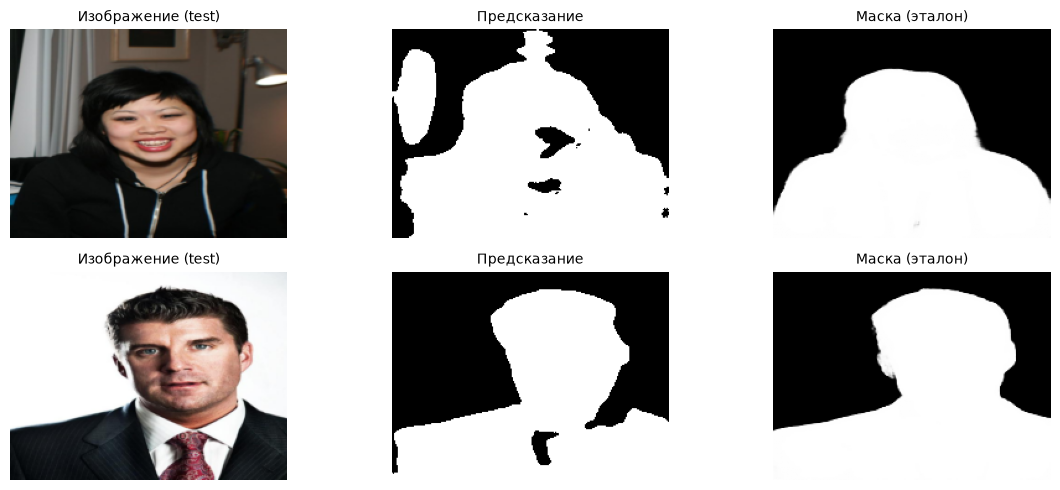

In [20]:
# как модель, переобучившаяся на батче, сегментирует сам батч...
preds_batch = get_preds(model, images_batch, device)
plot_triplets(images_batch.cpu(), masks_batch.cpu(), preds_batch,
              ("Изображение", "Предсказание", "Маска (эталон)"), figsize=(12, 5))

# ...и незнакомые картинки из test сразу после переобучения
test_show = np.random.default_rng(SEED + 3).choice(len(test_dataset), size=2, replace=False)
show_images = torch.stack([test_dataset[i][0] for i in test_show])
show_masks = torch.stack([test_dataset[i][1] for i in test_show])
preds_test = get_preds(model, show_images, device)
for k, i in enumerate(test_show):
    with torch.no_grad():
        logits = model(show_images[k:k + 1].to(device))
    inter = ((torch.sigmoid(logits) > THRESHOLD).float() * show_masks[k:k + 1].to(device)).sum()
    union = ((torch.sigmoid(logits) > THRESHOLD).float() + show_masks[k:k + 1].to(device)).sum() - inter
    print(f"test #{i}: jaccard = {(inter / (union + 1e-8)).item():.4f}")
plot_triplets(show_images, show_masks, preds_test,
              ("Изображение (test)", "Предсказание", "Маска (эталон)"), figsize=(12, 5))

**Итог эксперимента 1.** Модель переобучилась на батче (jaccard на батче близок к 1), а на тесте качество
осталось низким — сеть «запомнила» конкретные картинки и не обобщила. Сравнение с моделью, обученной на всех данных
(следующий эксперимент), показывает, насколько важно обучение на полной выборке.

## Эксперимент 2. Обучение на всём train

Обучаем базовую модель (U-Net, 16 начальных каналов) на всех 1400 изображениях train: **20 эпох**, batch = 8,
Adam, lr = 1e-3, BCEWithLogitsLoss (как в бенчмарк-ноутбуке задания). Раз в эпоху валидируем на отложенных
200 изображениях и сохраняем состояние с лучшим val jaccard — по кривым затем подберём оптимальное число шагов.

In [21]:
model = UNET(3, 16, 1).to(device)
print(f"Параметров модели: {sum(p.numel() for p in model.parameters()):,}")

t0 = time.perf_counter()
history, best_state = train_model(model, train_dataset, val_dataset, device,
                                  epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LEARNING_RATE)
print(f"\nПолное обучение заняло {time.perf_counter() - t0:.0f} с")

Параметров модели: 1,942,577


эпоха  1 | шаг   175/3500 | train loss 0.3250 jacc 0.7898 | val loss 0.2191 jacc 0.8538 | 169 с


эпоха  2 | шаг   350/3500 | train loss 0.1795 jacc 0.8771 | val loss 0.1778 jacc 0.8854 | 173 с


эпоха  3 | шаг   525/3500 | train loss 0.1348 jacc 0.9057 | val loss 0.1234 jacc 0.9193 | 171 с


эпоха  4 | шаг   700/3500 | train loss 0.1024 jacc 0.9288 | val loss 0.1220 jacc 0.9192 | 185 с


...

эпоха 16 | шаг  2800/3500 | train loss 0.0336 jacc 0.9758 | val loss 0.0681 jacc 0.9550 | 151 с


эпоха 17 | шаг  2975/3500 | train loss 0.0353 jacc 0.9744 | val loss 0.0664 jacc 0.9568 | 151 с


эпоха 18 | шаг  3150/3500 | train loss 0.0293 jacc 0.9786 | val loss 0.0710 jacc 0.9550 | 151 с


эпоха 19 | шаг  3325/3500 | train loss 0.0312 jacc 0.9771 | val loss 0.0791 jacc 0.9546 | 151 с


эпоха 20 | шаг  3500/3500 | train loss 0.0263 jacc 0.9809 | val loss 0.0675 jacc 0.9594 | 155 с

Полное обучение заняло 3466 с


In [22]:
steps_per_epoch = int(np.ceil(len(train_dataset) / BATCH_SIZE))
epochs = np.arange(1, EPOCHS + 1)
best_epoch = int(np.argmax(history["val_jaccard"])) + 1
best_val_jaccard = history["val_jaccard"][best_epoch - 1]

print(f"Лучшая эпоха по val jaccard: {best_epoch} "
      f"(= {best_epoch * steps_per_epoch} шагов из {EPOCHS * steps_per_epoch}, "
      f"val jaccard = {best_val_jaccard:.4f})")

train_table = pd.DataFrame({
    "steps": epochs * steps_per_epoch,
    "train_loss": np.round(history["train_loss"], 4),
    "val_loss": np.round(history["val_loss"], 4),
    "train_jaccard": np.round(history["train_jaccard"], 4),
    "val_jaccard": np.round(history["val_jaccard"], 4),
}, index=pd.Index(epochs, name="epoch"))
print(train_table.to_string())

Лучшая эпоха по val jaccard: 20 (= 3500 шагов из 3500, val jaccard = 0.9594)
       steps  train_loss  val_loss  train_jaccard  val_jaccard
epoch                                                         
1        175      0.3250    0.2191         0.7898       0.8538
2        350      0.1795    0.1778         0.8771       0.8854
3        525      0.1348    0.1234         0.9057       0.9193
4        700      0.1024    0.1220         0.9288       0.9192
5        875      0.0912    0.1289         0.9368       0.9251
6       1050      0.0794    0.1035         0.9446       0.9320
7       1225      0.0746    0.0813         0.9476       0.9430
8       1400      0.0585    0.0842         0.9591       0.9417
9       1575      0.0558    0.0874         0.9604       0.9427
10      1750      0.0526    0.0864         0.9625       0.9404
11      1925      0.0457    0.0731         0.9673       0.9514
12      2100      0.0429    0.0708         0.9695       0.9555
13      2275      0.0355    0.0702       

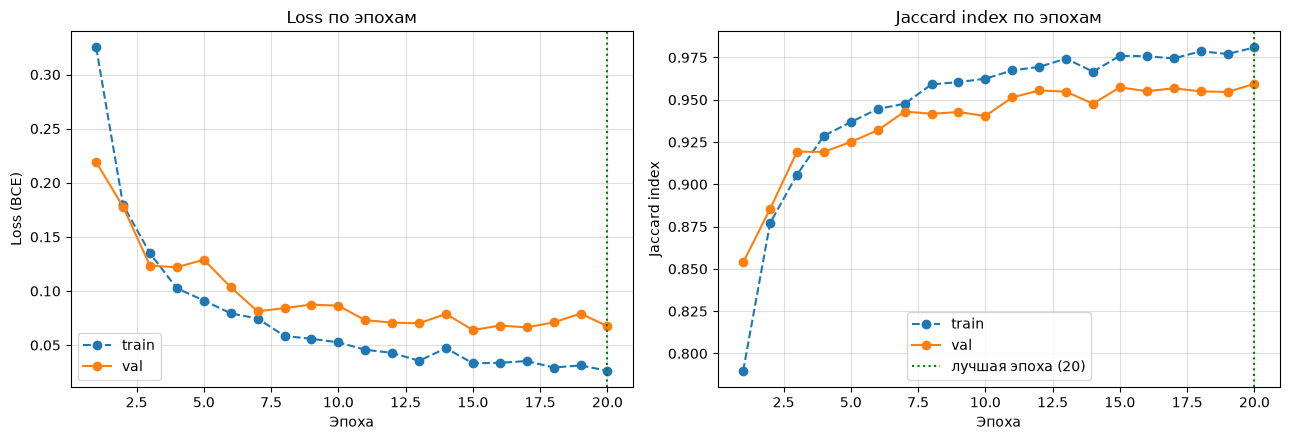

In [23]:
best_epoch = int(np.argmax(history["val_jaccard"])) + 1

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(epochs, history["train_loss"], linestyle="--", marker="o", label="train")
axes[0].plot(epochs, history["val_loss"], marker="o", label="val")
axes[0].axvline(best_epoch, color="green", linestyle=":", linewidth=1.5)
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss (BCE)")
axes[0].set_title("Loss по эпохам")
axes[0].legend()
axes[0].grid(True, alpha=0.4)

axes[1].plot(epochs, history["train_jaccard"], linestyle="--", marker="o", label="train")
axes[1].plot(epochs, history["val_jaccard"], marker="o", label="val")
axes[1].axvline(best_epoch, color="green", linestyle=":", linewidth=1.5,
                label=f"лучшая эпоха ({best_epoch})")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Jaccard index")
axes[1].set_title("Jaccard index по эпохам")
axes[1].legend()
axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

In [24]:
# итоговая модель: состояние лучшей эпохи
model.load_state_dict(best_state)
best_test_loss, best_test_jaccard = evaluate_loss_jaccard(model, test_dataset, device)

# модель, переобученная на одном батче (состояние из эксперимента 1)
overfit_model = UNET(3, 16, 1).to(device)
overfit_model.load_state_dict(overfit_state)
overfit_test_loss, overfit_test_jaccard = evaluate_loss_jaccard(overfit_model, test_dataset, device)

comparison_table = pd.DataFrame({
    "loss": [init_test_loss, overfit_test_loss, best_test_loss],
    "jaccard": [init_test_jaccard, overfit_test_jaccard, best_test_jaccard],
}, index=["до обучения (случайная инициализация)",
          "переобучение на одном батче (400 шагов)",
          f"полное обучение, лучшая эпоха ({best_epoch}, {best_epoch * steps_per_epoch} шагов)"])
print(comparison_table.round(4))

                                                  loss  jaccard
до обучения (случайная инициализация)           0.7014   0.4996
переобучение на одном батче (400 шагов)         1.2438   0.5344
полное обучение, лучшая эпоха (20, 3500 шагов)  0.0656   0.9609

In [25]:
# сохраняем обученные модели в кэш для последующих пунктов задания
cache_dir = NB_DIR.parent / "data" / "selfie_cache"
cache_dir.mkdir(parents=True, exist_ok=True)
torch.save(overfit_state, cache_dir / "task08_point1_overfit_batch.pt")
torch.save(best_state, cache_dir / "task08_point1_baseline_best.pt")
print(f"Модели сохранены в {cache_dir}")

Модели сохранены в /home/artemiipatov/development/my-ml/solutions/data/selfie_cache


test #167: jaccard = 0.9777
test #37: jaccard = 0.9116
test #139: jaccard = 0.9291


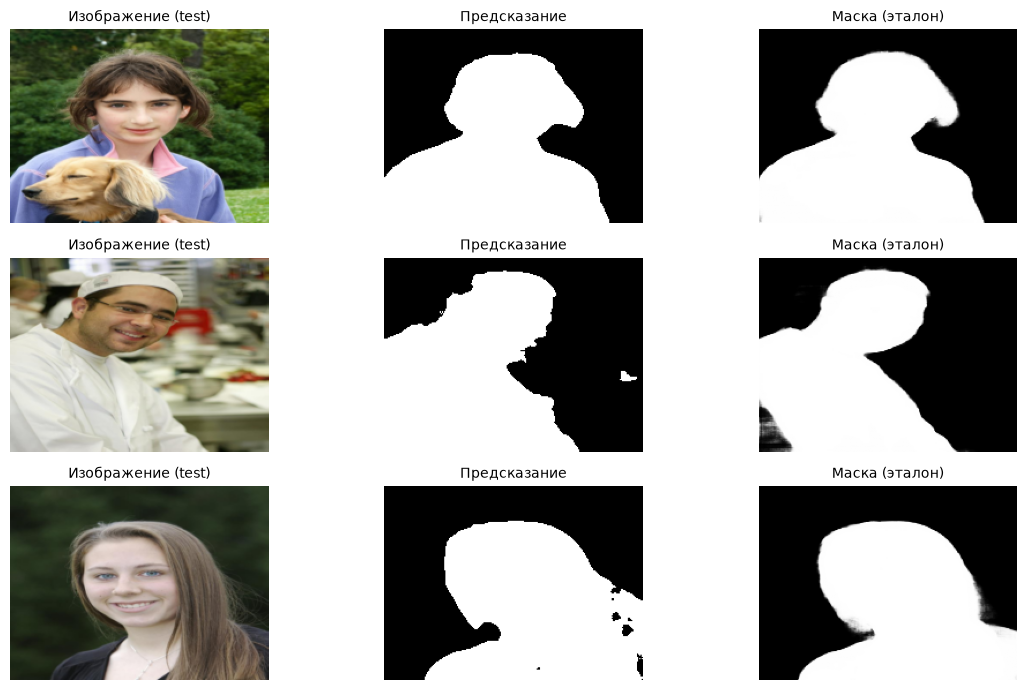

In [26]:
# примеры предсказаний рабочей модели на тесте
test_show = np.random.default_rng(SEED + 4).choice(len(test_dataset), size=3, replace=False)
show_images = torch.stack([test_dataset[i][0] for i in test_show])
show_masks = torch.stack([test_dataset[i][1] for i in test_show])
preds_show = get_preds(model, show_images, device)
for k, i in enumerate(test_show):
    with torch.no_grad():
        logits = model(show_images[k:k + 1].to(device))
    inter = ((torch.sigmoid(logits) > THRESHOLD).float() * show_masks[k:k + 1].to(device)).sum()
    union = ((torch.sigmoid(logits) > THRESHOLD).float() + show_masks[k:k + 1].to(device)).sum() - inter
    print(f"test #{i}: jaccard = {(inter / (union + 1e-8)).item():.4f}")
plot_triplets(show_images, show_masks, preds_show,
              ("Изображение (test)", "Предсказание", "Маска (эталон)"), figsize=(12, 7))

## Top-5 худших предсказаний на тесте

Считаем jaccard каждого объекта теста, сортируем по возрастанию и показываем пять худших примеров — по ним видно,
на каких изображениях модель ошибается сильнее всего.

Jaccard на тесте: min = 0.651, mean = 0.961, медиана = 0.978
Индексы худших предсказаний (в test): [np.int64(340), np.int64(23), np.int64(213), np.int64(91), np.int64(46)]


test #340: jaccard = 0.6508
test #23: jaccard = 0.6791
test #213: jaccard = 0.6795
test #91: jaccard = 0.7385
test #46: jaccard = 0.7416


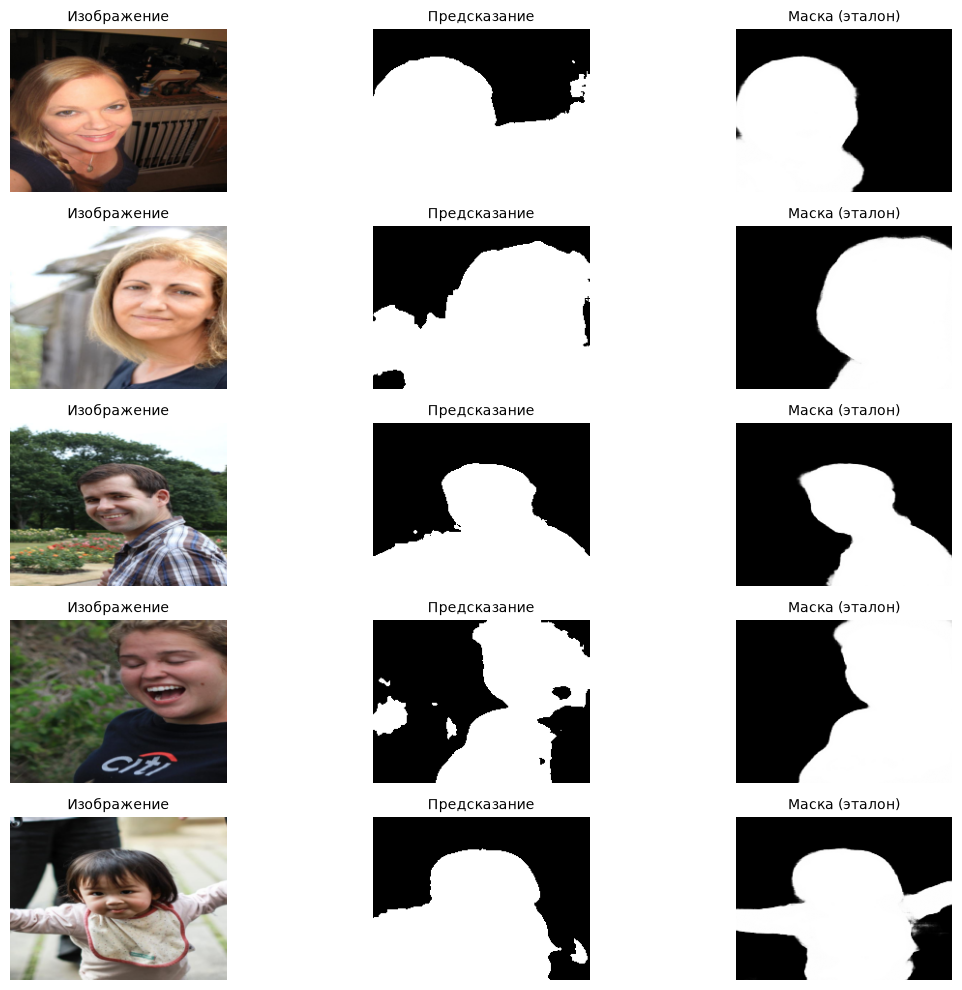

In [27]:
@torch.no_grad()
def per_sample_jaccard(model, dataset, device, batch_size=BATCH_SIZE):
    """Jaccard каждого объекта датасета (по порядку индексов)."""
    model.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    jaccards = []
    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)
        logits = model(images)
        preds = (torch.sigmoid(logits) > THRESHOLD).float()
        intersection = (preds * masks).sum(dim=(1, 2, 3))
        union = (preds + masks - preds * masks).sum(dim=(1, 2, 3))
        jaccards.extend((intersection / (union + 1e-8)).tolist())
    return np.array(jaccards)


test_jaccards = per_sample_jaccard(model, test_dataset, device)
worst_idx = np.argsort(test_jaccards)[:5]
print(f"Jaccard на тесте: min = {test_jaccards.min():.3f}, mean = {test_jaccards.mean():.3f}, "
      f"медиана = {np.median(test_jaccards):.3f}")
print("Индексы худших предсказаний (в test):", list(worst_idx))

worst_images = torch.stack([test_dataset[i][0] for i in worst_idx])
worst_masks = torch.stack([test_dataset[i][1] for i in worst_idx])
worst_preds = get_preds(model, worst_images, device)
for k, i in enumerate(worst_idx):
    print(f"test #{i}: jaccard = {test_jaccards[i]:.4f}")
plot_triplets(worst_images, worst_masks, worst_preds,
              ("Изображение", "Предсказание", "Маска (эталон)"), figsize=(12, 10))

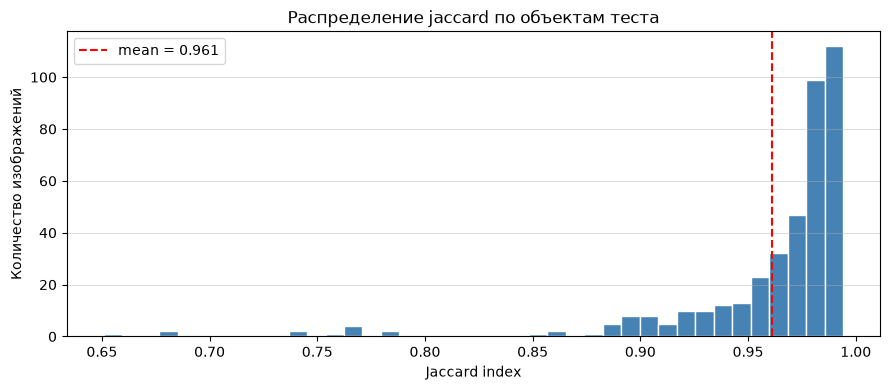

In [28]:
# гистограмма распределения jaccard по объектам теста
plt.figure(figsize=(9, 4))
plt.hist(test_jaccards, bins=40, color="steelblue", edgecolor="white")
plt.axvline(test_jaccards.mean(), color="red", linestyle="--", label=f"mean = {test_jaccards.mean():.3f}")
plt.xlabel("Jaccard index")
plt.ylabel("Количество изображений")
plt.title("Распределение jaccard по объектам теста")
plt.legend()
plt.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

## Анализ графиков

- **Кривые loss и jaccard по эпохам.** В первые ~7–8 эпох train и val loss быстро падают, а train и val jaccard быстро
  растут — на этом участке модель учится быстрее всего. Дальше скорость улучшения на глаз почти исчезает: после ~12-й
  эпохи val jaccard колеблется в узкой полосе (плато), а val loss — вокруг уровня ~0.07 без устойчивой динамики.
  Лучший val jaccard достигается на последней, 20-й эпохе: за 20 эпох явного переобучения не наступило, но и заметного
  прироста после выхода на плато нет. Train jaccard при этом продолжает медленно расти и к концу обучения на глаз
  заметно выше val — небольшое расхождение в пользу train видно в последние эпохи.
- **Переобучение на одном батче.** Кривая jaccard на батче резко вырастает с ~0.5 до ~0.97 уже к 50 шагам и дальше
  выходит на плато около 0.99 — ёмкости модели с запасом хватает, чтобы запомнить 4 картинки.
- **Предсказания на тесте.** У рабочей модели силуэт человека на глаз хорошо совпадает с эталонной маской; заметные
  ошибки — неточные границы (сглаженные, срезанные края рук и головы).
- **Худшие предсказания.** На худших примерах видно общее: сложные позы, размытые фото, части человека вне кадра,
  а также фон, по цвету похожий на одежду или кожу — модель путает такие участки с человеком.

## Выводы

- **Разбиение и воспроизводимость.** Данные разделены на train 1400 / val 200 / test 400; все сиды зафиксированы
  (перестановки при разбиении, NumPy, PyTorch, генератор DataLoader'а), поэтому результаты более-менее воспроизводятся.
- **Переобучение на одном батче.** На 4 фиксированных картинках модель сходится к jaccard ≈ 0.99 на самом батче уже
  к 50–75 шагам (loss ≈ 0.03) — ёмкости U-Net достаточно, чтобы «выучить» конкретные примеры, процедура обучения
  корректна. При этом на тесте jaccard остаётся низким (0.53 против 0.50 у случайной инициализации): модель запомнила
  примеры, но не обобщила.
- **Обучение на всём train.** Модель обучилась на 1400 изображениях; лучший val jaccard достигается на эпохе
  **20 из 20** (шаг **3500 из 3500** при фиксированных параметрах Adam, lr = 1e-3, batch = 8) — за 20 эпох явное
  переобучение не наступило. Визуально после ~15-й эпохи (2625 шагов) кривые выходят на плато: прирост качества дальше
  минимален, так что при ограничении по времени разумно останавливаться уже там, а оптимальным числом шагов считать
  всю доступную длину обучения (3500 шагов).
- **Тест.** Модель лучшей эпохи достигает на тесте jaccard ≈ **0.961** (loss 0.066) против 0.500 у случайной
  инициализации и 0.534 у модели, переобученной на батче.
- **Худшие предсказания.** Jaccard по тесту высокий на большинстве объектов (медиана ≈ 0.978); в top-5 худших
  (0.65–0.74) попадают изображения со сложными позами, размытием, обрезанными частями тела и фоном, похожим по цвету
  на человека; на остальных объектах модель ошибается в основном только на границах силуэта.